# Multi-Digit Sequence Recognition — Google Colab GPU Runner (L4 / T4 / A100)

**Hỗ trợ chạy trực tiếp trong Antigravity IDE (qua Google Colab Extension) hoặc trên trình duyệt Colab.**

- Chọn Kernel **Google Colab** có GPU (**L4 GPU** khuyến nghị, hoặc T4/A100).
- Notebook này **tự chứa toàn bộ mã nguồn `src/` và `configs/`** (tương tự cơ chế turnkey của `cv3d`), tự tải dataset `fellahabdelnour13/multidigit-mnist` (52.7 MB) về ổ đĩa NVMe `/content/` trên VM Colab nên **không cần push GitHub hay upload code thủ công**.

In [16]:
#@title ⚙️ 0. Cấu hình Pipeline (Colab L4 GPU)
KAGGLE_DATASET_SLUG = "fellahabdelnour13/multidigit-mnist"  #@param {type:"string"}
EPOCHS = 35  #@param {type:"integer"}
BATCH_SIZE = 64  #@param {type:"integer"}
NUM_WORKERS = 2  #@param {type:"integer"}
AUTO_RESUME = False  #@param {type:"boolean"}
SAVE_TO_GOOGLE_DRIVE = True  #@param {type:"boolean"}
DRIVE_OUTPUT_DIR = "multi-digit-sequence-recognition"  #@param {type:"string"}

print(f"Dataset slug : {KAGGLE_DATASET_SLUG}")
print(f"Epochs       : {EPOCHS} | Batch size: {BATCH_SIZE} | Workers: {NUM_WORKERS} | Auto-resume: {AUTO_RESUME}")
print(f"Save to Drive: {SAVE_TO_GOOGLE_DRIVE} (MyDrive/{DRIVE_OUTPUT_DIR})")

Dataset slug : fellahabdelnour13/multidigit-mnist
Epochs       : 35 | Batch size: 64 | Workers: 2 | Auto-resume: False
Save to Drive: True (MyDrive/multi-digit-sequence-recognition)


In [17]:
#@title 🔌 1. Kiểm tra GPU (L4/T4/A100) & Kết nối Google Drive (tuỳ chọn)
import torch
from pathlib import Path

!nvidia-smi
assert torch.cuda.is_available(), "Chưa có GPU! Hãy chọn Colab Kernel có GPU (L4/T4/A100)."
print(f"✅ GPU sẵn sàng: {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB VRAM)")

DRIVE_DIR = None
if SAVE_TO_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_DIR = Path(f"/content/drive/MyDrive/{DRIVE_OUTPUT_DIR}")
        (DRIVE_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)
        (DRIVE_DIR / "outputs").mkdir(parents=True, exist_ok=True)
        print(f"✅ Đã kết nối Google Drive: {DRIVE_DIR}")
    except Exception as exc:
        print(f"⚠️ Không mount được Google Drive ({exc}). Kết quả vẫn được lưu tại /content/.")
        DRIVE_DIR = None

Tue Nov 17 17:01:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   38C    P8             12W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [18]:
#@title 📦 2. Khôi phục mã nguồn repo vào /content/ & Cài thư viện
import base64, io, zipfile
from pathlib import Path

WORK_DIR = Path("/content/multi-digit-sequence-recognition")
WORK_DIR.mkdir(parents=True, exist_ok=True)

# Compressed bundle of 21 repo files (src/ and configs/)
REPO_BUNDLE_B64 = "..."

with zipfile.ZipFile(io.BytesIO(base64.b64decode(REPO_BUNDLE_B64))) as zf:
    file_count = len(zf.namelist())
    zf.extractall(WORK_DIR)

print(f"✅ Đã giải nén {file_count} file mã nguồn & config vào {WORK_DIR}")
%cd /content/multi-digit-sequence-recognition
!pip install -q pyyaml tqdm kagglehub kaggle

✅ Đã giải nén 21 file mã nguồn & config vào /content/multi-digit-sequence-recognition
/content/multi-digit-sequence-recognition


In [19]:
#@title ⬇️ 3. Tải dataset & Kiểm tra / Chia tập train-val-test
import os
from pathlib import Path

# Đọc Kaggle credentials nếu bạn lưu trong Colab Secrets (không bắt buộc với dataset public)
try:
    from google.colab import userdata
    for key in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        try:
            val = userdata.get(key)
            if val:
                os.environ[key] = val
        except Exception:
            pass
except Exception:
    pass

raw_png_count = len(list(Path("data/raw").rglob("*.png"))) if Path("data/raw").exists() else 0
if raw_png_count == 0:
    !python src/download_data.py --config configs/colab_gpu.yaml --slug "{KAGGLE_DATASET_SLUG}"
else:
    print(f"ℹ️ Đã có sẵn {raw_png_count} ảnh trong data/raw/, bỏ qua bước tải lại.")

!python src/inspect_data.py --config configs/colab_gpu.yaml

ℹ️ Đã có sẵn 60000 ảnh trong data/raw/, bỏ qua bước tải lại.
Inspecting raw dataset in: /content/multi-digit-sequence-recognition/data/raw
Validating dataset: 100% 60001/60001 [00:05<00:00, 11523.60file/s]
Validation report:
{
  "total_files_scanned": 60001,
  "valid_samples": 60000,
  "rejected_samples": 1,
  "rejection_counts": {
    "unsupported_format": 1,
    "duplicate_path": 0,
    "corrupted_image": 0,
    "missing_label": 0,
    "missing_label_delimiter": 0,
    "empty_sequence": 0,
    "invalid_label_characters": 0,
    "unexpected_sequence_length": 0
  },
  "rejection_examples": [
    {
      "path": "/content/multi-digit-sequence-recognition/data/raw/main.py",
      "reason": "unsupported_format",
      "detail": ".py"
    }
  ],
  "sequence_length_distribution": {
    "1": 1680,
    "2": 15009,
    "3": 15003,
    "4": 14843,
    "5": 13465
  },
  "metadata_csv": "/content/multi-digit-sequence-recognition/data/processed/metadata.csv"
}
Labels with non-digit characters: 0
S

In [20]:
#@title 🚀 4. Huấn luyện trên Colab GPU (ReduceLROnPlateau + Scheduled Teacher Forcing)
from pathlib import Path
import shutil

resume_arg = ""
local_final = Path("checkpoints/final_model.pt")
if AUTO_RESUME:
    if DRIVE_DIR is not None:
        drive_final = DRIVE_DIR / "checkpoints" / "final_model.pt"
        drive_best = DRIVE_DIR / "checkpoints" / "best_model.pt"
        Path("checkpoints").mkdir(parents=True, exist_ok=True)
        if drive_final.exists() and not local_final.exists():
            shutil.copy2(drive_final, local_final)
        if drive_best.exists() and not Path("checkpoints/best_model.pt").exists():
            shutil.copy2(drive_best, Path("checkpoints/best_model.pt"))
    if local_final.exists():
        resume_arg = "--resume checkpoints/final_model.pt"
        print("♻️ Phát hiện checkpoints/final_model.pt -> tiếp tục train (resume)!")
else:
    print("🆕 Train mới từ Epoch 1 với ReduceLROnPlateau & scheduled teacher forcing (0.8 -> 0.3).")

!python src/train.py --config configs/colab_gpu.yaml --device cuda --epochs {EPOCHS} --batch-size {BATCH_SIZE} --num-workers {NUM_WORKERS} {resume_arg}

🆕 Train mới từ Epoch 1 với ReduceLROnPlateau & scheduled teacher forcing (0.8 -> 0.3).
Training on device: cuda | batch_size=64 | num_workers=2 | train=42500 | val=7500
Epoch 1/35 [train]: 100% 665/665 [00:20<00:00, 31.87it/s, loss=0.8187]
Epoch 1/35 | lr=0.001 | tf=0.80 | train_loss=0.8187 | val_loss=0.7872 | val_exact_acc=0.4144 | val_cer=0.3541
Epoch 2/35 [train]: 100% 665/665 [00:18<00:00, 36.71it/s, loss=0.5333]
Epoch 2/35 | lr=0.001 | tf=0.79 | train_loss=0.5333 | val_loss=0.6542 | val_exact_acc=0.4448 | val_cer=0.3406
Epoch 3/35 [train]: 100% 665/665 [00:18<00:00, 35.26it/s, loss=0.4514]
Epoch 3/35 | lr=0.001 | tf=0.77 | train_loss=0.4514 | val_loss=0.7648 | val_exact_acc=0.3992 | val_cer=0.3460
Epoch 4/35 [train]: 100% 665/665 [00:18<00:00, 35.94it/s, loss=0.3769]
Epoch 4/35 | lr=0.001 | tf=0.76 | train_loss=0.3769 | val_loss=0.4714 | val_exact_acc=0.5651 | val_cer=0.2352
Epoch 5/35 [train]: 100% 665/665 [00:18<00:00, 35.82it/s, loss=0.3260]
Epoch 5/35 | lr=0.001 | tf=0.74 | tr

Evaluation results on 'test' split:
{
  "recognition": {
    "total_samples": 10000,
    "exact_matches": 8169,
    "exact_sequence_accuracy": 0.8169,
    "character_accuracy": 0.9120979640011803,
    "cer": 0.08790203599881971,
    "total_true_chars": 33890,
    "total_edit_distance": 2979
  },
  "numerical_equal_length": {
    "status": "ok",
    "note": "Computed on aligned digit positions from the subset of samples whose predicted and ground-truth lengths match (excluding PAD, SOS, and EOS tokens).",
    "total_samples": 10000,
    "equal_length_samples": 9956,
    "coverage": 0.9956,
    "num_digit_positions": 33753,
    "r2": 0.7876442843440905,
    "nse": 0.7876442843440905,
    "mae": 0.3402067964329097,
    "rmse": 1.3043732234747747
  },
  "split": "test",
  "loss": 0.21261441380165186
}
Sample 1: True=22589 | Pred=22589
Sample 2: True=6146 | Pred=6146
Sample 3: True=57 | Pred=57
Sample 4: True=732 | Pred=732
Sample 5: True=81 | Pred=81
Saved prediction grid: /content/multi-d

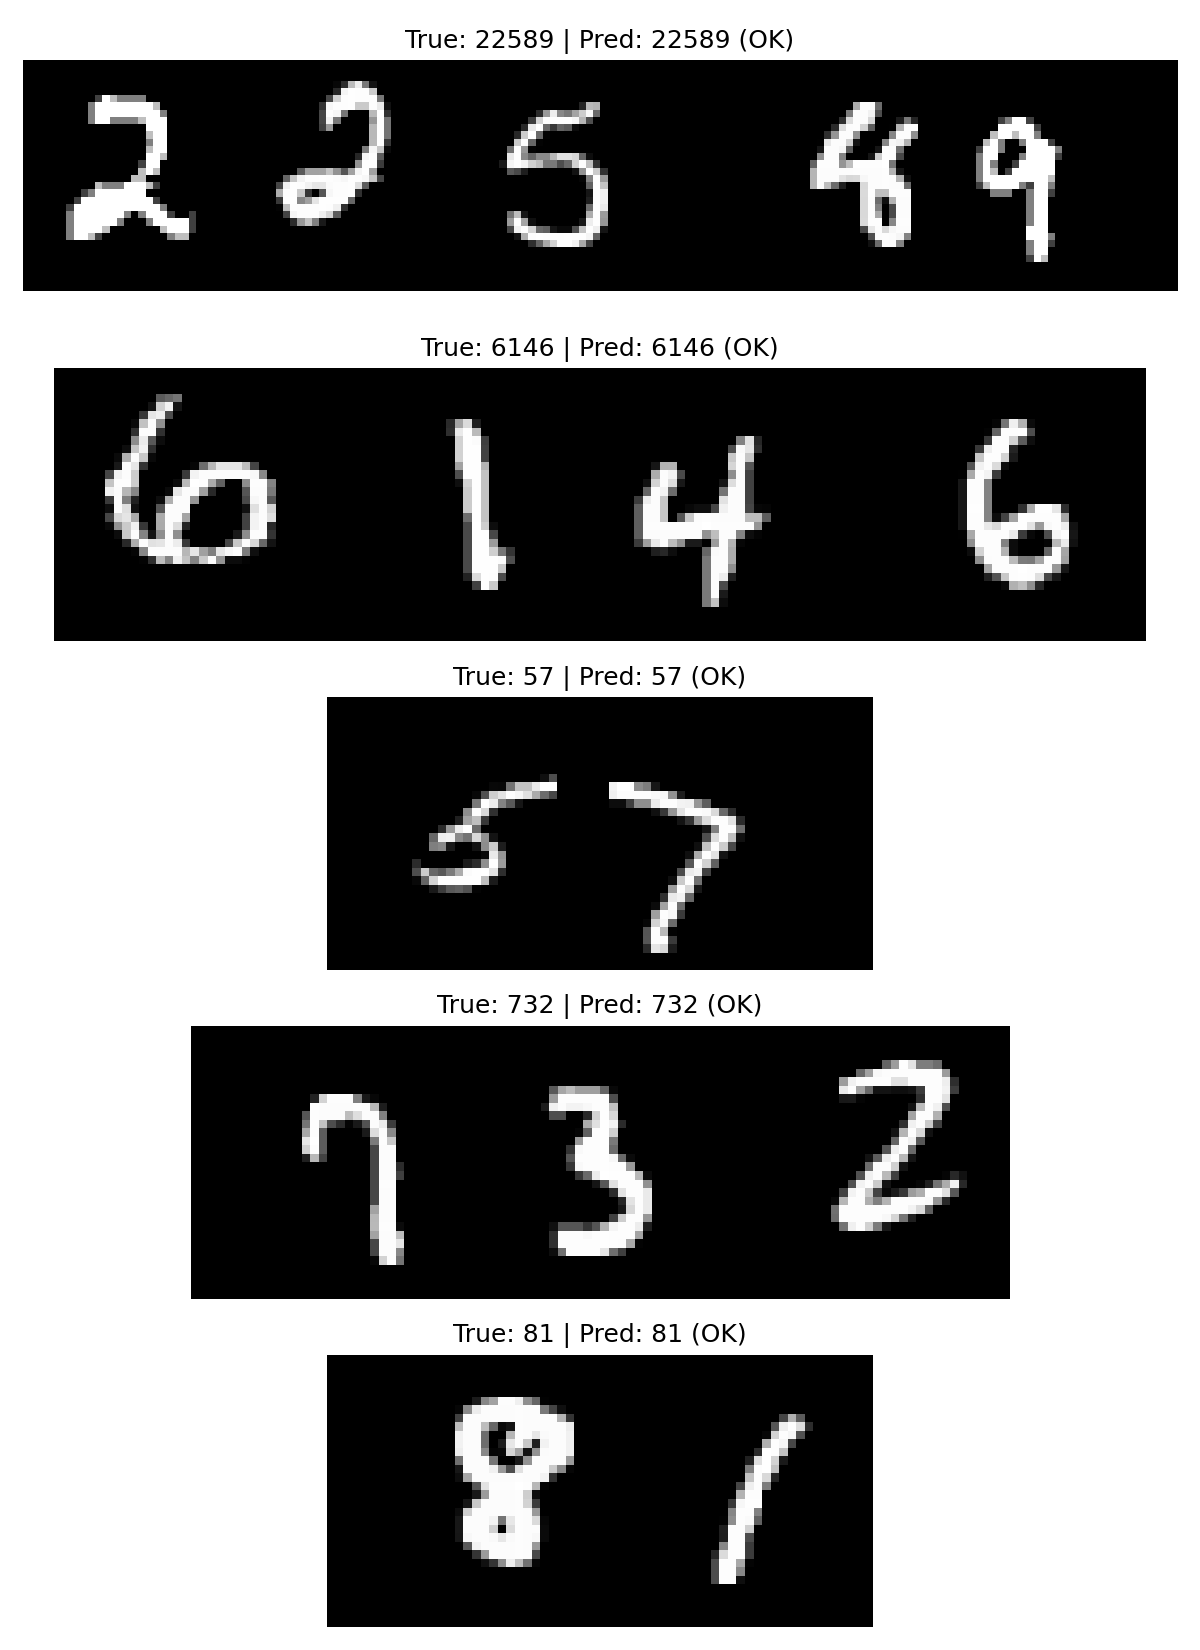


--- outputs/demo_attention.png ---


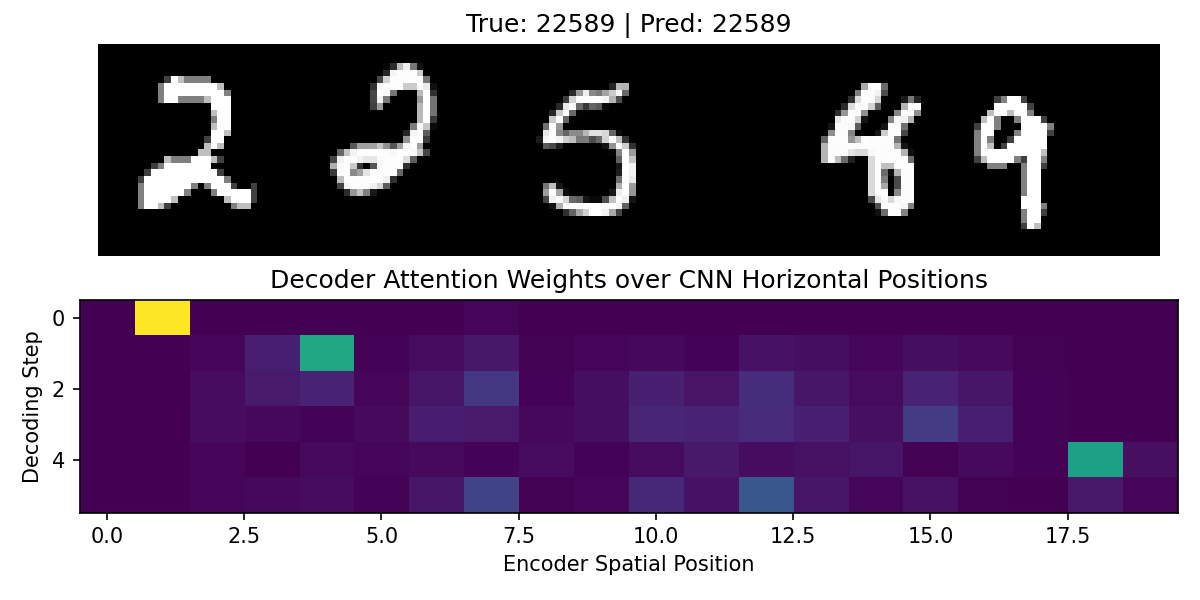

In [21]:
#@title 📊 5. Đánh giá trên tập Test & Hiển thị kết quả trực quan
import json
from pathlib import Path
from IPython.display import Image as IPyImage, display

!python src/evaluate.py --config configs/colab_gpu.yaml --checkpoint checkpoints/best_model.pt --split test --device cuda --batch-size {BATCH_SIZE} --num-workers {NUM_WORKERS}
!python src/demo.py --config configs/colab_gpu.yaml --checkpoint checkpoints/best_model.pt --split test --num-samples 5 --device cuda

metrics_path = Path("outputs/test_metrics.json")
if metrics_path.exists():
    print("\n=== TEST METRICS ===")
    print(json.dumps(json.loads(metrics_path.read_text(encoding="utf-8")), indent=2))

for img_path in ["outputs/demo_predictions.png", "outputs/demo_attention.png"]:
    if Path(img_path).exists():
        print(f"\n--- {img_path} ---")
        display(IPyImage(filename=img_path))

In [22]:
#@title 💾 6. Lưu checkpoints & outputs sang Google Drive + Tự tải colab_results.zip
import shutil
import zipfile
from pathlib import Path

zip_path = Path("/content/colab_results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for folder in ("checkpoints", "outputs"):
        src_dir = Path(folder)
        if src_dir.exists():
            for file_path in sorted(src_dir.rglob("*")):
                if file_path.is_file() and file_path.name != ".gitkeep":
                    zf.write(file_path, arcname=file_path.as_posix())

print(f"📦 Đã đóng gói checkpoints/ + outputs/ tại: {zip_path} ({zip_path.stat().st_size / (1024**2):.2f} MB)")

if DRIVE_DIR is not None:
    for folder in ("checkpoints", "outputs"):
        src_dir = Path(folder)
        if src_dir.exists():
            shutil.copytree(src_dir, DRIVE_DIR / folder, dirs_exist_ok=True)
    shutil.copy2(zip_path, DRIVE_DIR / zip_path.name)
    print(f"☁️ Đã lưu lên Google Drive: {DRIVE_DIR / zip_path.name}")

# Tự kích hoạt tải xuống khi chạy trên trình duyệt Google Colab
try:
    from google.colab import files
    files.download(str(zip_path))
    print("⬇️ Đang tải colab_results.zip về máy (nếu dùng Colab trên trình duyệt).")
except Exception as exc:
    print(f"ℹ️ Không tự bật tải file qua IDE ({exc}). Hãy tải {zip_path.name} từ Google Drive về Downloads rồi chạy: python scripts/pull_colab_results.py")

📦 Đã đóng gói checkpoints/ + outputs/ tại: /content/colab_results.zip (25.67 MB)
☁️ Đã lưu lên Google Drive: /content/drive/MyDrive/multi-digit-sequence-recognition/colab_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ Đang tải colab_results.zip về máy (nếu dùng Colab trên trình duyệt).
